# ⛰️ Lesson 8: Optimization: How Models Actually Learn
**Week 7 · Notebook 8 of 10 · ⏱️ about 120 minutes**

---

## 🎯 Learning objectives
By the end of this lesson you will be able to:

1. **Distinguish** a *loss function* (one example) from a *cost function* (the whole dataset), and choose sensible ones.
2. **Explain** gradient descent with the "hiker in the fog" picture, and **derive** its update rule for linear regression.
3. **Implement** gradient descent from scratch in NumPy and watch it converge.
4. **Diagnose learning rates** that are too small, just right, or too large.
5. **Recognise convergence** and apply stopping criteria; explain why **feature scaling** speeds it up.
6. **Compare** batch, stochastic and mini-batch gradient descent, and apply the same machinery to **logistic regression**.

## 🗺️ Roadmap
`Learning = optimisation` → `Loss & cost` → `Gradient descent` → `Learning rates` → `Convergence` → `Variants` → `Logistic regression` → **Problems**

> 🧮 This lesson has the most math in the course. **Don't panic.** Every formula is accompanied by a picture, a hand-worked example and runnable code. If a symbol scares you, find it in the code: it is always one line of NumPy.

In [1]:
import sys
sys.path.append("..")
from course_utils import *
setup()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

---
# 📖 Part 1: Learning is optimisation

Every model we've trained has **parameters**: numbers like the slope and intercept. Training means *finding the parameter values that make the model's predictions as good as possible*. That is an **optimisation problem**, and every optimisation problem in ML has the same four ingredients:

| Ingredient | In linear regression |
|---|---|
| **Model**: a function with adjustable parameters | ŷ = w·x + b |
| **Loss function**: how wrong is the model on *one* example? | (ŷ − y)² |
| **Cost function**: average loss over the *whole* training set | J(w, b) = (1/n) Σ (ŷᵢ − yᵢ)² |
| **Optimiser**: a procedure that changes the parameters to lower the cost | gradient descent |

> 🌫️ **The hiker in the fog.** You're on a mountainside in thick fog and want to reach the valley. You can't see the valley, but you *can* feel the **slope under your feet**. So you take a step in the **steepest downhill direction**, feel the slope again, step again… Eventually the ground flattens: you've reached the bottom. **That is gradient descent.** The mountain is the cost function; your position is the parameters; the slope is the gradient.

---
# 📖 Part 2: Loss functions and cost functions

**Loss** = penalty on a single prediction. **Cost** = average loss across the dataset. (Terminology varies; some books use them interchangeably. We'll keep them separate.)

Different loss functions encode different opinions about mistakes:

| Task | Loss | Formula (per example) | Character |
|---|---|---|---|
| Regression | **Squared error** (MSE) | (y − ŷ)² | punishes big errors heavily; smooth |
| Regression | **Absolute error** (MAE) | \|y − ŷ\| | robust to outliers; kink at 0 |
| Regression | **Huber** | squared near 0, linear far away | best of both |
| Classification | **Log loss** (cross-entropy) | −[y·log p + (1−y)·log(1−p)] | punishes confident wrong answers brutally |

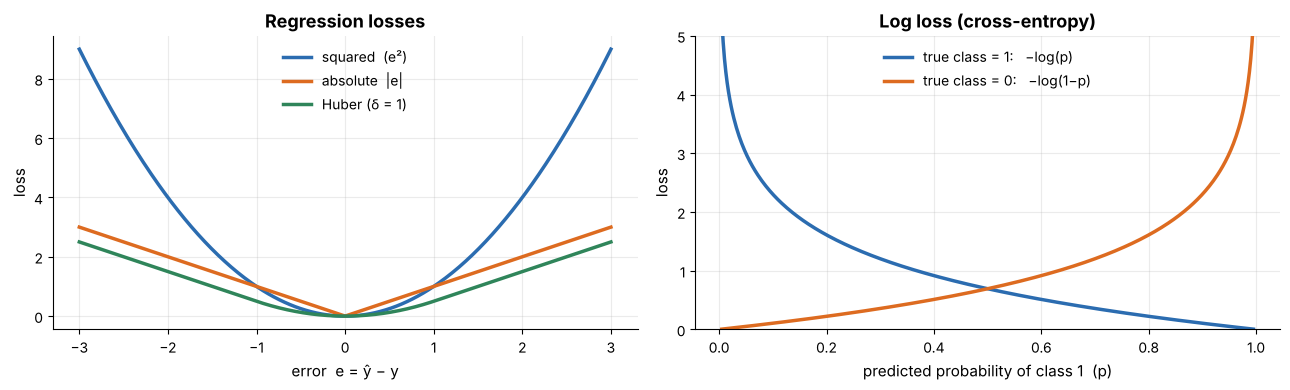

In [2]:
e = np.linspace(-3, 3, 400)
huber = np.where(np.abs(e) <= 1, 0.5 * e ** 2, np.abs(e) - 0.5)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(e, e ** 2, color=BLUE, lw=2.5, label="squared  (e²)")
axes[0].plot(e, np.abs(e), color=ORANGE, lw=2.5, label="absolute  |e|")
axes[0].plot(e, huber, color=GREEN, lw=2.5, label="Huber (δ = 1)")
axes[0].set_xlabel("error  e = ŷ − y"); axes[0].set_ylabel("loss"); axes[0].set_title("Regression losses"); axes[0].legend()

p = np.linspace(0.005, 0.995, 400)
axes[1].plot(p, -np.log(p), color=BLUE, lw=2.5, label="true class = 1:   −log(p)")
axes[1].plot(p, -np.log(1 - p), color=ORANGE, lw=2.5, label="true class = 0:   −log(1−p)")
axes[1].set_ylim(0, 5); axes[1].set_xlabel("predicted probability of class 1  (p)"); axes[1].set_ylabel("loss")
axes[1].set_title("Log loss (cross-entropy)"); axes[1].legend()
plt.tight_layout(); plt.show()

* **Left:** an error of 3 costs 9 under squared loss but only 3 under absolute loss: squared loss "panics" about outliers, which is why a regression trained on MSE can be dragged around by a few extreme points. Huber behaves like squared loss near zero (smooth, easy to optimise) and like absolute loss far away (robust).
* **Right:** if the true class is 1 and the model says p = 0.99, the loss is tiny; if it says p = 0.01 (confidently wrong), the loss is huge and *keeps growing as p → 0*. Log loss pushes models toward **honest probabilities**, not just right answers.

### 🧑‍🏫 Worked Example 1: A cost function you can see

Three data points that follow exactly **y = 2x** (so the perfect slope is **w = 2**, with b = 0): x = [1, 2, 3], y = [2, 4, 6]. Using the model ŷ = w·x, the cost is

$$J(w) = \frac{1}{3}\sum_{i}(w x_i - y_i)^2 .$$

*By hand:*
* **w = 0:** predictions 0, 0, 0 → errors −2, −4, −6 → squares 4, 16, 36 → J = 56 ÷ 3 = **18.67**
* **w = 1:** predictions 1, 2, 3 → errors −1, −2, −3 → squares 1, 4, 9 → J = 14 ÷ 3 = **4.67**
* **w = 2:** perfect → J = **0**
* **w = 3:** errors +1, +2, +3 → J = **4.67** (again!)

The cost is a **parabola** with its bottom at w = 2. Let me confirm with code:

J(w=0) = 18.67
J(w=1) = 4.67
J(w=2) = 0.00
J(w=3) = 4.67


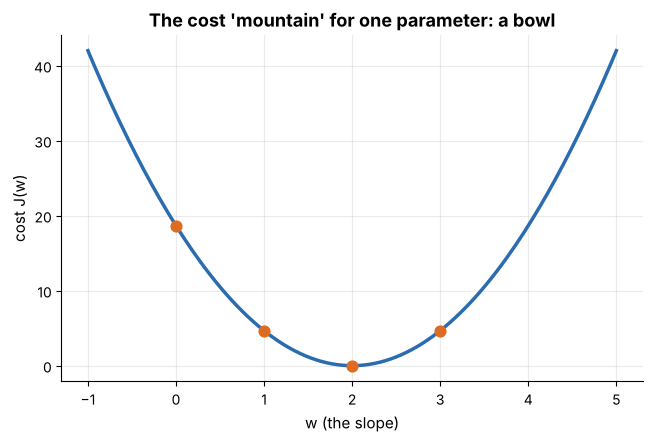

In [3]:
x_toy, y_toy = np.array([1., 2., 3.]), np.array([2., 4., 6.])
J = lambda w: np.mean((w * x_toy - y_toy) ** 2)

for w in [0, 1, 2, 3]:
    print(f"J(w={w}) = {J(w):.2f}")

ws = np.linspace(-1, 5, 200)
plt.plot(ws, [J(w) for w in ws], color=BLUE, lw=2.5)
plt.scatter([0, 1, 2, 3], [J(w) for w in [0, 1, 2, 3]], color=ORANGE, zorder=3, s=60)
plt.xlabel("w (the slope)"); plt.ylabel("cost J(w)"); plt.title("The cost 'mountain' for one parameter: a bowl")
plt.show()

Training = *find the bottom of the bowl.* Notice something lovely: at any point **the slope of the bowl tells us which way is downhill**. Slope positive (right of the minimum) → decrease w. Slope negative (left) → increase w. That's the whole idea of the next section.

---
# 📖 Part 3: Gradient descent

The **gradient** is the slope of the cost with respect to each parameter. The **update rule** is a single line:

$$\boxed{\; w \;\leftarrow\; w \;-\; \alpha \cdot \frac{\partial J}{\partial w} \;}$$

* **∂J/∂w** (the gradient): the slope at the current point. Positive → going uphill to the right.
* **α (alpha)**, the **learning rate**: how big a step we take. A hyperparameter!
* The **minus sign** is the "descent": step *against* the slope.

For linear regression with ŷ = w·x + b, calculus gives (try deriving it, using the chain rule; the power rule brings down a 2):

$$\frac{\partial J}{\partial w} = \frac{2}{n}\sum_i (\hat y_i - y_i)\,x_i \qquad\qquad \frac{\partial J}{\partial b} = \frac{2}{n}\sum_i (\hat y_i - y_i)$$

In words: **the gradient is the average error, weighted by the input.** If the model under-predicts for large x, then `w` is pushed up.

### 🧑‍🏫 Worked Example 2: Two gradient-descent steps by hand

Same toy data (x = [1,2,3], y = [2,4,6]), model ŷ = w·x (no bias), start at **w = 0**, learning rate **α = 0.1**. Here ∂J/∂w = (2/3) Σ (w xᵢ − yᵢ) xᵢ.

**Step 1** (w = 0): errors (ŷ − y) = −2, −4, −6; multiply by x → −2, −8, −18; sum = −28; gradient = (2/3)(−28) = **−18.67**. 
Update: w = 0 − 0.1 × (−18.67) = **1.867**. *(Big negative slope → we step right, a long way.)*

**Step 2** (w = 1.867): errors = 1.867·[1,2,3] − [2,4,6] = −0.133, −0.267, −0.400; × x → −0.133, −0.533, −1.200; sum = −1.867; gradient = (2/3)(−1.867) = **−1.244**.
Update: w = 1.867 + 0.1244 = **1.991**. *(Gentler slope → a smaller step. We're almost at the answer, 2.)*

Notice the steps **shrink automatically** as the slope flattens: gradient descent slows down near the bottom. Code agrees:

In [4]:
w, alpha = 0.0, 0.1
for step in range(1, 6):
    grad = 2 * np.mean((w * x_toy - y_toy) * x_toy)          # ∂J/∂w
    w = w - alpha * grad                                      # the update rule
    print(f"step {step}:  gradient = {grad:8.3f}   →   w = {w:.4f}   (cost {J(w):.5f})")

step 1:  gradient =  -18.667   →   w = 1.8667   (cost 0.08296)
step 2:  gradient =   -1.244   →   w = 1.9911   (cost 0.00037)
step 3:  gradient =   -0.083   →   w = 1.9994   (cost 0.00000)
step 4:  gradient =   -0.006   →   w = 2.0000   (cost 0.00000)
step 5:  gradient =   -0.000   →   w = 2.0000   (cost 0.00000)


### Did I get the derivative right?: a numerical check

A trick every practitioner uses: compare the analytic gradient with a **finite-difference** approximation, `(J(w+ε) − J(w−ε)) / 2ε`. If they agree, your calculus is right.

In [5]:
w0, eps = 0.7, 1e-6
analytic = 2 * np.mean((w0 * x_toy - y_toy) * x_toy)
numeric = (J(w0 + eps) - J(w0 - eps)) / (2 * eps)
print(f"analytic gradient: {analytic:.6f}\nnumeric gradient : {numeric:.6f}")

analytic gradient: -12.133333
numeric gradient : -12.133333


## Gradient descent for real: line fitting on the students data

Now with **two** parameters (slope `w` and intercept `b`) on real data: `exam_score` vs `hours_studied`. The "mountain" now has two coordinates (w, b) and the cost is a bowl in 3-D: we'll draw it as a **contour map** (like a hiking map: each ring is a height).

In [6]:
students = load("students.csv")
x_raw, y_raw = students["hours_studied"].to_numpy(), students["exam_score"].to_numpy()

def gradient_descent(x, y, lr, n_iter, w=0.0, b=0.0):
    """Batch gradient descent for ŷ = w·x + b with the MSE cost. Returns final (w, b), cost history, and the path."""
    history, path = [], [(w, b)]
    for _ in range(n_iter):
        err = w * x + b - y                     # ŷ − y   for every example
        history.append(np.mean(err ** 2))       # cost J(w, b)
        grad_w = 2 * np.mean(err * x)           # ∂J/∂w
        grad_b = 2 * np.mean(err)               # ∂J/∂b
        w, b = w - lr * grad_w, b - lr * grad_b # simultaneous update
        path.append((w, b))
    return w, b, np.array(history), np.array(path)

w_gd, b_gd, hist, path = gradient_descent(x_raw, y_raw, lr=0.01, n_iter=3000)
w_cf, b_cf = np.polyfit(x_raw, y_raw, 1)                      # the exact (closed-form) least-squares answer
print(f"gradient descent : w = {w_gd:.4f}   b = {b_gd:.4f}")
print(f"exact solution   : w = {w_cf:.4f}   b = {b_cf:.4f}")
print(f"cost went from {hist[0]:.0f} (parameters at 0,0) to {hist[-1]:.2f}")

gradient descent : w = 3.9763   b = 35.0139
exact solution   : w = 3.9762   b = 35.0142
cost went from 3294 (parameters at 0,0) to 25.23


Gradient descent, starting from `w = b = 0`, found essentially the same line as the exact algebraic solution. For linear regression we *could* skip the iteration, but for logistic regression, neural networks and almost everything else, **there is no formula, and gradient descent is the only game in town.**

### Why scaling matters: a tale of two mountains

Our hours range from 0.5 to 10 while the intercept "feels" a unit change very differently: the cost bowl is a **long, narrow valley**: gradient descent first lurches sideways toward the valley wall (the steep direction), then has to *crawl* along the flat valley floor. If we **standardise** `x`, the valley becomes a nice round bowl and the path goes nearly straight to the bottom:

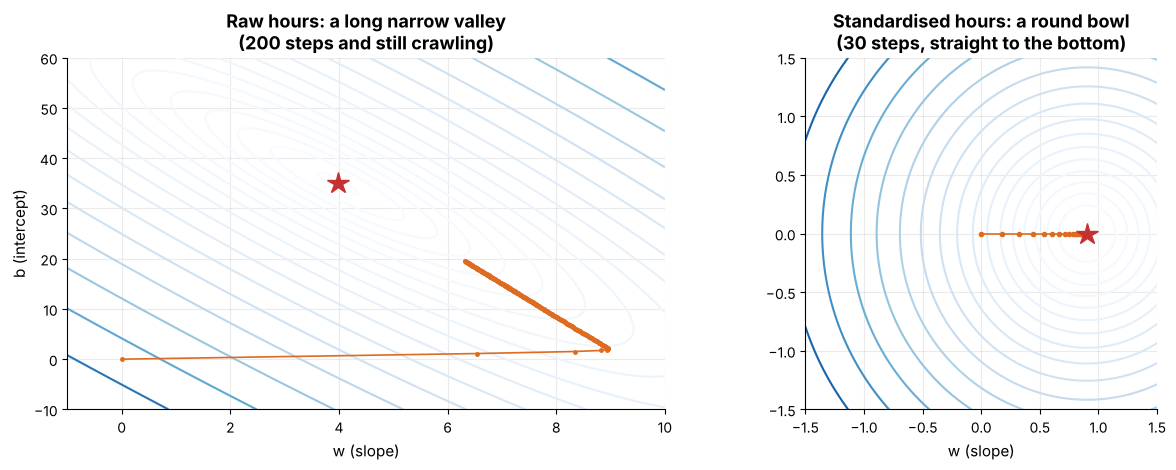

In [7]:
xs = (x_raw - x_raw.mean()) / x_raw.std()
ys = (y_raw - y_raw.mean()) / y_raw.std()

def cost_surface(x, y, wr, br):
    W, B = np.meshgrid(wr, br)
    return W, B, np.mean((W[..., None] * x + B[..., None] - y) ** 2, axis=-1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
# (a) raw features
_, _, _, p_raw = gradient_descent(x_raw, y_raw, lr=0.01, n_iter=200)
W, B, Z = cost_surface(x_raw, y_raw, np.linspace(-1, 10, 200), np.linspace(-10, 60, 200))
axes[0].contour(W, B, Z, levels=np.geomspace(Z.min() + 1, Z.max(), 18), cmap="Blues")
axes[0].plot(*p_raw.T, "o-", color=ORANGE, ms=2.5, lw=1.2); axes[0].plot(w_cf, b_cf, "*", color=RED, ms=16)
axes[0].set_title("Raw hours: a long narrow valley\n(200 steps and still crawling)"); axes[0].set_xlabel("w (slope)"); axes[0].set_ylabel("b (intercept)")
# (b) standardised features
_, _, _, p_std = gradient_descent(xs, ys, lr=0.1, n_iter=30)
W, B, Z = cost_surface(xs, ys, np.linspace(-1.5, 1.5, 150), np.linspace(-1.5, 1.5, 150))
axes[1].contour(W, B, Z, levels=np.geomspace(Z.min() + 0.01, Z.max(), 18), cmap="Blues")
axes[1].plot(*p_std.T, "o-", color=ORANGE, ms=3, lw=1.2); axes[1].plot(*np.polyfit(xs, ys, 1), "*", color=RED, ms=16)
axes[1].set_title("Standardised hours: a round bowl\n(30 steps, straight to the bottom)"); axes[1].set_xlabel("w (slope)")
axes[1].set_aspect("equal", adjustable="box")
plt.tight_layout(); plt.show()

The red star is the exact minimum. **Left:** after 200 steps we are still crawling along the valley floor. **Right:** after 30 steps we have arrived. Scaling features doesn't change the *answer*: it changes **how many steps it takes to find it.** (Another reason, after distance-based methods and regularisation, to always standardise.)

---
# 📖 Part 4: The learning rate α: the Goldilocks hyperparameter

* **Too small:** you inch downhill: correct, but painfully slow.
* **Just right:** fast and smooth.
* **Too large:** you *overshoot* the valley floor and land higher on the other side; each step makes it worse; the cost **explodes** (divergence).

On the standardised data the math is clean: the cost is a perfectly round bowl, and gradient descent **converges whenever α < 1** and diverges for α > 1. Let's try six learning rates:

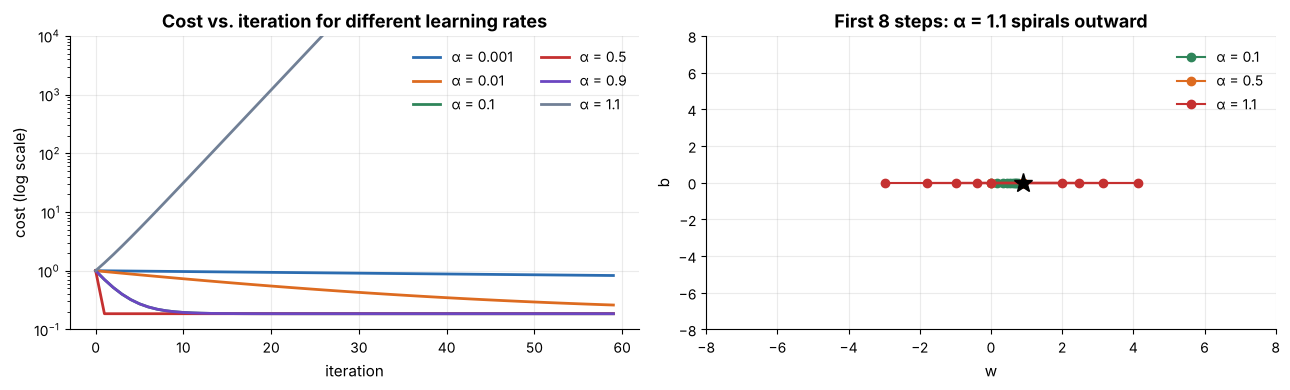

In [8]:
rates = [0.001, 0.01, 0.1, 0.5, 0.9, 1.1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for lr, c in zip(rates, PALETTE + [BLUE]):
    *_, h, _ = gradient_descent(xs, ys, lr=lr, n_iter=60)
    axes[0].plot(h, color=c, lw=2, label=f"α = {lr}")
axes[0].set_yscale("log"); axes[0].set_ylim(1e-1, 1e4)
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("cost (log scale)"); axes[0].set_title("Cost vs. iteration for different learning rates"); axes[0].legend(ncol=2)

for lr, c in zip([0.1, 0.5, 1.1], [GREEN, ORANGE, RED]):
    *_, p_ = gradient_descent(xs, ys, lr=lr, n_iter=8)
    axes[1].plot(p_[:, 0], p_[:, 1], "o-", color=c, label=f"α = {lr}")
axes[1].set_xlim(-8, 8); axes[1].set_ylim(-8, 8); axes[1].plot(*np.polyfit(xs, ys, 1), "*", color="k", ms=14)
axes[1].set_xlabel("w"); axes[1].set_ylabel("b"); axes[1].set_title("First 8 steps: α = 1.1 spirals outward"); axes[1].legend()
plt.tight_layout(); plt.show()

| α | What we see |
|---|---|
| **0.001** | cost barely moves: would need thousands of iterations |
| **0.01** | steady decline, reaches the floor in a few hundred steps |
| **0.1** | quick, smooth |
| **0.5** | converges almost instantly (on this perfectly round bowl, exactly one step) |
| **0.9** | overshoots back and forth but still shrinks (oscillates) |
| **1.1** | **diverges**: each step lands further away; cost grows without bound |

**Practical advice:** try learning rates on a log scale (…, 0.001, 0.01, 0.1, 1, …); plot the cost curve; if it **rises or zigzags wildly, lower α**; if it falls but crawls, raise it. Modern optimisers (Adam, RMSProp, learning-rate schedules) adapt α automatically, but the logic is the same.

---
# 📖 Part 5: Convergence: when do we stop?

Gradient descent never "finishes" on its own; we need a **stopping rule**. Common ones:

1. **Maximum iterations** (a safety net, always include).
2. **Cost-change tolerance:** stop when `|J_old − J_new| < tol`: improvement has become negligible.
3. **Gradient tolerance:** stop when the gradient's length is near 0: we're on flat ground.
4. **Validation-based (early stopping):** stop when validation error stops improving (Lesson 4).

### 🧑‍🏫 Worked Example 3: How many steps does each tolerance need?

In [9]:
def gd_until_converged(x, y, lr, tol, max_iter=100_000):
    w = b = 0.0
    prev = np.inf
    for i in range(1, max_iter + 1):
        err = w * x + b - y
        cost = np.mean(err ** 2)
        if abs(prev - cost) < tol:                         # improvement is negligible → converged
            return w, b, i
        prev = cost
        w, b = w - lr * 2 * np.mean(err * x), b - lr * 2 * np.mean(err)
    return w, b, max_iter

for tol in [1e-2, 1e-4, 1e-6, 1e-8]:
    w_, b_, n_ = gd_until_converged(xs, ys, lr=0.1, tol=tol)
    print(f"tol = {tol:<7.0e} → stopped after {n_:>3} iterations   (w = {w_:.5f}, b = {b_:.5f})")
# A fair comparison: how many iterations until the cost is within 0.1% of the true minimum?
def iterations_to_near_optimal(x, y, lr, max_iter=20_000):
    w_opt, b_opt = np.polyfit(x, y, 1)
    target = np.mean((w_opt * x + b_opt - y) ** 2) * 1.001
    w = b = 0.0
    with np.errstate(all="ignore"):
        for i in range(1, max_iter + 1):
            err = w * x + b - y
            if np.mean(err ** 2) < target:
                return i
            w, b = w - lr * 2 * np.mean(err * x), b - lr * 2 * np.mean(err)
    return None                                         # never got there (too slow, or diverged)

print("\niterations needed to get within 0.1% of the best possible cost:")
print(f"  raw hours,          α = 0.025 (about the largest stable value): {iterations_to_near_optimal(x_raw, y_raw, 0.025)}")
print(f"  raw hours,          α = 0.030 (just too big!)                 : {iterations_to_near_optimal(x_raw, y_raw, 0.030)}   (None = diverged)")
print(f"  standardised hours, α = 0.1                                   : {iterations_to_near_optimal(xs, ys, 0.1)}")

tol = 1e-02   → stopped after  10 iterations   (w = 0.78149, b = -0.00000)
tol = 1e-04   → stopped after  20 iterations   (w = 0.88963, b = 0.00000)
tol = 1e-06   → stopped after  31 iterations   (w = 0.90152, b = 0.00000)
tol = 1e-08   → stopped after  41 iterations   (w = 0.90252, b = 0.00000)

iterations needed to get within 0.1% of the best possible cost:
  raw hours,          α = 0.025 (about the largest stable value): 468


  raw hours,          α = 0.030 (just too big!)                 : None   (None = diverged)
  standardised hours, α = 0.1                                   : 20


Tighter tolerance → more iterations, with diminishing returns: the first few digits of the answer settle early. And look at the fair comparison: unscaled hours need roughly **20× more iterations** than standardised hours (and tolerate only a tiny learning rate; 0.03 already diverges, while on standardised data anything below 1 is safe). Scaling pays off again.

### Convex vs. non-convex: will we always find the best answer?

* The MSE cost of **linear regression is convex** (a single bowl): gradient descent always reaches the *global* minimum (given a sensible α).
* Many other models (neural networks!) have **non-convex** costs with several valleys. Where you *start* determines which valley you roll into.

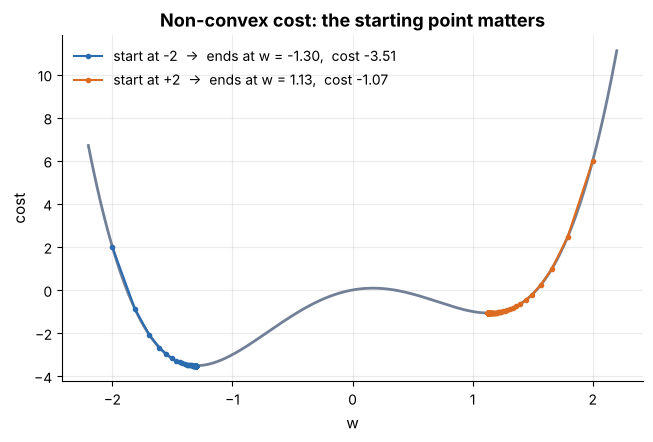

In [10]:
f = lambda w: w ** 4 - 3 * w ** 2 + w
df = lambda w: 4 * w ** 3 - 6 * w + 1

ws = np.linspace(-2.2, 2.2, 400)
plt.plot(ws, f(ws), color=GREY, lw=2)
for start, c in [(-2.0, BLUE), (2.0, ORANGE)]:
    w, trail = start, [start]
    for _ in range(200):
        w -= 0.01 * df(w); trail.append(w)
    plt.plot(trail, f(np.array(trail)), "o-", color=c, ms=3, label=f"start at {start:+.0f}  →  ends at w = {w:.2f},  cost {f(w):.2f}")
plt.xlabel("w"); plt.ylabel("cost"); plt.title("Non-convex cost: the starting point matters"); plt.legend(); plt.show()

Two starting points, **two different answers**: one lands in the deep (global) valley, the other in a shallower (local) one. In practice we fight this with random restarts (remember `n_init` in K-Means!), better initialisation, momentum, and noise from mini-batches.

---
# 📖 Part 6: Batch, stochastic and mini-batch gradient descent

So far each step used **all** the training examples (**batch** gradient descent). With a million rows, one step is expensive. Alternatives:

| Variant | Examples per update | Behaviour |
|---|---|---|
| **Batch** | all *n* | smooth, accurate gradient, but slow per step |
| **Stochastic (SGD)** | 1 | very cheap, very noisy, jitters around the minimum |
| **Mini-batch** | e.g. 16–256 | the sweet spot; what practically everyone uses |

The mini-batch gradient is a **noisy estimate** of the true gradient, but on average it points the right way, and we get *many* more updates for the same computing budget.

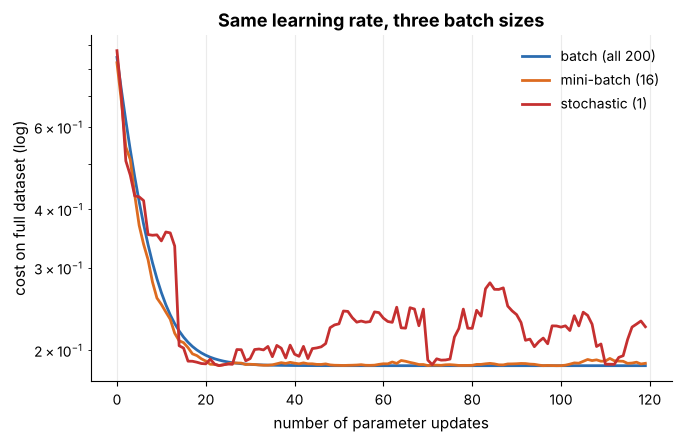

In [11]:
def minibatch_gd(x, y, lr, batch_size, n_updates, seed=0):
    rng = np.random.default_rng(seed)
    w = b = 0.0
    curve = []
    for _ in range(n_updates):
        idx = rng.choice(len(x), size=batch_size, replace=False)    # sample a mini-batch
        err = w * x[idx] + b - y[idx]
        w, b = w - lr * 2 * np.mean(err * x[idx]), b - lr * 2 * np.mean(err)
        curve.append(np.mean((w * x + b - y) ** 2))                   # evaluate on ALL data (for plotting only)
    return np.array(curve)

for bs, c, name in [(len(xs), BLUE, "batch (all 200)"), (16, ORANGE, "mini-batch (16)"), (1, RED, "stochastic (1)")]:
    plt.plot(minibatch_gd(xs, ys, lr=0.05, batch_size=bs, n_updates=120), color=c, lw=2, label=name)
plt.yscale("log"); plt.xlabel("number of parameter updates"); plt.ylabel("cost on full dataset (log)")
plt.title("Same learning rate, three batch sizes"); plt.legend(); plt.show()

Batch descent is smooth; **SGD is noisy** and keeps jittering around the minimum rather than settling; **mini-batch** is a good compromise. This noise is not purely bad: it can help an optimiser bounce out of poor local minima in non-convex problems. (In scikit-learn's `SGDRegressor` from Lesson 4, *this* is what `partial_fit` does under the hood.)

---
# 📖 Part 7: The same machinery for classification: logistic regression

Logistic regression predicts a **probability** by squashing a linear score through the **sigmoid** function:

$$p = \sigma(z) = \frac{1}{1+e^{-z}}, \qquad z = w_1x_1 + \dots + w_dx_d + b$$

Its cost is the **log loss** (from Part 2), and (here's the beautiful part) its gradient has *exactly the same shape* as linear regression's, just with `p` in place of `ŷ`:

$$\frac{\partial J}{\partial w_j} = \frac{1}{n}\sum_i (p_i - y_i)\,x_{ij} \qquad\qquad \frac{\partial J}{\partial b} = \frac{1}{n}\sum_i (p_i - y_i)$$

Let's train logistic regression **from scratch** on the churn data and compare with scikit-learn.

                 our gradient descent  scikit-learn
tenure_months                  -0.894        -0.894
monthly_charge                  0.354         0.355
support_calls                   0.356         0.356
contract_months                -0.953        -0.951
late_payments                   0.498         0.498
usage_gb                       -0.172        -0.172

intercept: ours -2.368  vs  sklearn -2.367


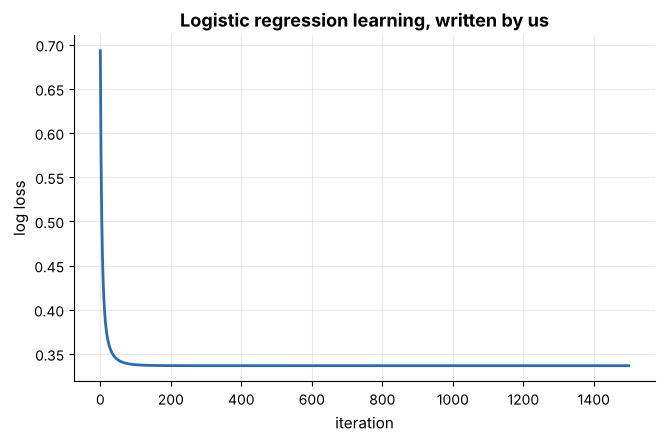

In [12]:
churn = load("churn.csv")
Xc = StandardScaler().fit_transform(churn.drop(columns="churned"))
yc = churn["churned"].to_numpy()

sigmoid = lambda z: 1 / (1 + np.exp(-z))

w, b = np.zeros(Xc.shape[1]), 0.0
loss_curve = []
for i in range(1500):
    p = sigmoid(Xc @ w + b)
    loss_curve.append(-np.mean(yc * np.log(p) + (1 - yc) * np.log(1 - p)))      # log loss
    w -= 0.5 * (Xc.T @ (p - yc)) / len(yc)                                     # gradient step for the weights
    b -= 0.5 * np.mean(p - yc)                                                  # gradient step for the bias

sk = LogisticRegression(C=1e10, max_iter=5000).fit(Xc, yc)                      # (huge C ≈ no regularisation)
print(pd.DataFrame({"our gradient descent": w, "scikit-learn": sk.coef_[0]}, index=churn.columns[:-1]).round(3))
print(f"\nintercept: ours {b:.3f}  vs  sklearn {sk.intercept_[0]:.3f}")
plt.plot(loss_curve, color=BLUE, lw=2); plt.xlabel("iteration"); plt.ylabel("log loss"); plt.title("Logistic regression learning, written by us"); plt.show()

**Our 12-line gradient descent reproduces scikit-learn's coefficients.** There's no mystery inside `LogisticRegression.fit`: it's this loop (with a smarter optimiser and some extra safety features). Neural networks use the same loop too; only the formulas for the gradient get longer (and a library, *backpropagation*, computes them automatically).

### 🧭 The big picture

```
 data ─▶ model(parameters) ─▶ predictions ─▶ loss/cost ─▶ gradient ─▶ update parameters ─┐
                  ▲                                                                       │
                  └───────────────────────────── repeat until convergence ◀───────────────┘
```

---
# 🧩 Your turn: Problems

### 🧩 Problem 8.1: Compute a cost &nbsp; ⭐

Write `mse_cost(w, b, x, y)` returning the mean squared error of the line `ŷ = w·x + b` on the data.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`y_hat = w * x + b`, then `np.mean((y_hat - y) ** 2)`.

</details>

In [ ]:
def mse_cost(w, b, x, y):
    return None

In [ ]:
# ✔ Self-check - run this after you have solved the problem
_x, _y = np.array([1., 2., 3.]), np.array([2., 4., 6.])
check("J(w=0, b=0) = 56/3", lambda: abs(mse_cost(0, 0, _x, _y) - 56 / 3) < 1e-9)
check("J(w=2, b=0) = 0", lambda: abs(mse_cost(2, 0, _x, _y)) < 1e-12)
check("J(w=1, b=1) = (0 + 1 + 4)/3... computed: errors −0, −1, −2", lambda: abs(mse_cost(1, 1, _x, _y) - (0 + 1 + 4) / 3) < 1e-9)

### 🧩 Problem 8.2: One gradient step by hand &nbsp; ⭐⭐

Data: `x = [1, 2, 3, 4]`, `y = [3, 5, 7, 9]` (the exact line y = 2x + 1). Start at `w = 0, b = 0` with learning rate `0.05`.

Compute the two gradients `grad_w`, `grad_b` for the MSE cost, then the updated parameters `w_new`, `b_new` after **one** step.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`err = w*x + b - y`; `grad_w = 2 * mean(err * x)`; `grad_b = 2 * mean(err)`.

</details>

<details>
<summary>💡 Hint 2</summary>

`w_new = w - lr * grad_w` (and likewise for b). Both should move *up*, since the true values (2 and 1) are larger than the starting values.

</details>

In [ ]:
x = np.array([1., 2., 3., 4.]); y = np.array([3., 5., 7., 9.])
w, b, lr = 0.0, 0.0, 0.05

grad_w = grad_b = w_new = b_new = None
print(grad_w, grad_b, w_new, b_new)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("grad_w = −35", lambda: abs(grad_w + 35) < 1e-9)
check("grad_b = −12", lambda: abs(grad_b + 12) < 1e-9)
check("w_new = 1.75", lambda: abs(w_new - 1.75) < 1e-9)
check("b_new = 0.6", lambda: abs(b_new - 0.6) < 1e-9)

### 🧩 Problem 8.3: Verify a gradient numerically &nbsp; ⭐⭐

Write `numerical_gradient(f, w, eps=1e-6)` returning the **central finite-difference** approximation `(f(w+eps) − f(w−eps)) / (2·eps)` for a function of one variable.

Use it to check the analytic gradient of `J(w) = mean((w·x − y)²)` at `w = 0.7` on the data below: store the numeric gradient in `num_grad` and the analytic one `2·mean((w·x − y)·x)` in `ana_grad`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Central differences use points on *both* sides of w: `f(w + eps)` and `f(w - eps)`.

</details>

In [ ]:
x = np.array([1., 2., 3.]); y = np.array([2., 4., 6.])
J = lambda w: np.mean((w * x - y) ** 2)

def numerical_gradient(f, w, eps=1e-6):
    return None

num_grad = ana_grad = None
print(num_grad, ana_grad)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("numerical_gradient works on f(w)=w² at w=3 (→ 6)", lambda: abs(numerical_gradient(lambda w: w ** 2, 3.0) - 6) < 1e-6)
check("numeric and analytic gradients agree to 6 decimals", lambda: abs(num_grad - ana_grad) < 1e-6)
check("the analytic gradient at 0.7 is −(2/3)·(1.3·14) ≈ −16.8×… (negative)", lambda: ana_grad < 0)

### 🧩 Problem 8.4: Write gradient descent &nbsp; ⭐⭐

Implement `gradient_descent(x, y, lr, n_iter)` for the line ŷ = w·x + b with the MSE cost. Start from `w = b = 0` and return `(w, b, history)`, where `history` is a list of the **cost before each update**.

Then run it on data generated from the line **y = 4x + 7** (no noise) with `lr = 0.1` and `n_iter = 500`, storing the result in `w_fit, b_fit, hist`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Inside the loop: compute `err = w*x + b - y`, append `np.mean(err**2)` to `history`, then update `w` and `b` with the two gradients.

</details>

<details>
<summary>💡 Hint 2</summary>

`grad_w = 2*np.mean(err*x)` and `grad_b = 2*np.mean(err)`; update **both** using the *old* error vector (compute both gradients before changing either parameter).

</details>

In [ ]:
def gradient_descent(x, y, lr, n_iter):
    w, b, history = 0.0, 0.0, []
    # your loop here
    return w, b, history

x_data = np.linspace(-1, 1, 50)
y_data = 4 * x_data + 7                    # the secret line
w_fit, b_fit, hist = gradient_descent(x_data, y_data, lr=0.1, n_iter=500)
print(w_fit, b_fit)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("slope recovered (≈ 4)", lambda: abs(w_fit - 4) < 0.01)
check("intercept recovered (≈ 7)", lambda: abs(b_fit - 7) < 0.01)
check("cost decreased at every iteration", lambda: all(np.diff(hist) <= 1e-12))
check("final cost is tiny (< 1e-4)", lambda: hist[-1] < 1e-4)

### 🧩 Problem 8.5: Find the best learning rate &nbsp; ⭐⭐

On the standardised student data (provided), run gradient descent (from `w = b = 0`) for each `lr` in `[0.001, 0.01, 0.1, 0.5, 1.1]`, for **at most 1000 iterations**.

For each rate, record the **number of iterations needed** until the cost is within `1e-6` of the *optimal* cost (the optimum is provided as `opt_cost`). If the rate never gets there (too slow, or diverging), record `None`.

Store the results in `iterations` (`{lr: n or None}`) and the rate that needed the fewest iterations in `best_lr`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Inside the loop, compute the cost each iteration and stop at the first `i` where `cost < opt_cost + 1e-6`.

</details>

<details>
<summary>💡 Hint 2</summary>

Diverging runs may overflow to `inf`/`nan`; comparisons with `nan` are `False`, so they simply never satisfy the condition, which is exactly what we want.

</details>

In [ ]:
students = load("students.csv")
xs = ((students["hours_studied"] - students["hours_studied"].mean()) / students["hours_studied"].std()).to_numpy()
ys = ((students["exam_score"] - students["exam_score"].mean()) / students["exam_score"].std()).to_numpy()
opt_w, opt_b = np.polyfit(xs, ys, 1)
opt_cost = np.mean((opt_w * xs + opt_b - ys) ** 2)

rates = [0.001, 0.01, 0.1, 0.5, 1.1]
iterations = {}
best_lr = None
print(iterations, best_lr)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("results for all five rates", lambda: sorted(iterations) == sorted(rates))
check("α = 1.1 never converges (diverges)", lambda: iterations[1.1] is None)
check("α = 0.001 is too slow for 1000 iterations", lambda: iterations[0.001] is None)
check("α = 0.01 converges, but needs hundreds of iterations", lambda: iterations[0.01] is not None and iterations[0.01] > 100)
check("α = 0.5 is the fastest", lambda: best_lr == 0.5)

### 🧩 Problem 8.6: Stop when it's converged &nbsp; ⭐⭐

Write `gd_with_tol(x, y, lr, tol, max_iter=100000)` that runs gradient descent from `w = b = 0` and **stops as soon as the cost decreases by less than `tol`** between iterations. Return `(w, b, n_iter)`.

Run it on standardised student data (provided) with `lr = 0.1` for `tol = 1e-3` and `tol = 1e-8`; store the iteration counts in `n_loose` and `n_tight`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Track `prev_cost` (start with `np.inf`). At each iteration compute the current cost; if `abs(prev_cost - cost) < tol`, return.

</details>

<details>
<summary>💡 Hint 2</summary>

Remember to update `prev_cost = cost` and then update the parameters.

</details>

In [ ]:
students = load("students.csv")
xs = ((students["hours_studied"] - students["hours_studied"].mean()) / students["hours_studied"].std()).to_numpy()
ys = ((students["exam_score"] - students["exam_score"].mean()) / students["exam_score"].std()).to_numpy()

def gd_with_tol(x, y, lr, tol, max_iter=100000):
    w = b = 0.0
    return w, b, 0

_, _, n_loose = gd_with_tol(xs, ys, 0.1, 1e-3)
w_tight, b_tight, n_tight = gd_with_tol(xs, ys, 0.1, 1e-8)
print(n_loose, n_tight)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
_w, _b = np.polyfit(xs, ys, 1)
check("a tighter tolerance needs more iterations", lambda: n_tight > n_loose > 1)
check("both stop long before max_iter (< 1000)", lambda: n_tight < 1000)
check("the tight run is very close to the exact solution (within 0.001)", lambda: abs(w_tight - _w) < 1e-3 and abs(b_tight - _b) < 1e-3)

### 🧩 Problem 8.7: Logistic regression from scratch &nbsp; ⭐⭐⭐

Implement `fit_logistic_gd(X, y, lr, n_iter)` using **only NumPy**. It starts from zeros and returns `(w, b, losses)`, where `losses` is the log loss *before each update*.

The gradients are `X.T @ (p − y) / n` for `w` and `mean(p − y)` for `b`, with `p = sigmoid(X @ w + b)`.

Train it on the standardised churn data (provided; `lr = 0.5`, `n_iter = 1000`) and store the training accuracy at a 0.5 threshold in `my_acc`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`sigmoid = lambda z: 1 / (1 + np.exp(-z))`.

</details>

<details>
<summary>💡 Hint 2</summary>

Log loss: `-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))`.

</details>

<details>
<summary>💡 Hint 3</summary>

Predicted class: `(sigmoid(X @ w + b) >= 0.5).astype(int)`; accuracy is `np.mean(pred == y)`.

</details>

In [ ]:
churn = load("churn.csv")
X = StandardScaler().fit_transform(churn.drop(columns="churned"))
y = churn["churned"].to_numpy()

def fit_logistic_gd(X, y, lr, n_iter):
    w, b, losses = np.zeros(X.shape[1]), 0.0, []
    # your loop here
    return w, b, losses

w, b, losses = fit_logistic_gd(X, y, lr=0.5, n_iter=1000)
my_acc = None
print(my_acc)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
_ref = LogisticRegression(C=1e10, max_iter=5000).fit(X, y)
check("log loss decreases", lambda: losses[-1] < losses[0] and np.all(np.diff(losses) < 1e-9))
check("weights match scikit-learn (max difference < 0.01)", lambda: np.max(np.abs(w - _ref.coef_[0])) < 0.01)
check("accuracy matches scikit-learn's", lambda: abs(my_acc - _ref.score(X, y)) < 0.005)

---
## 🎟️ Exit ticket

**Q1.** What's the difference between a loss function and a cost function?
**Q2.** Write the gradient-descent update rule in words. Why is there a minus sign?
**Q3.** Your cost goes *up* every iteration and eventually shows `inf`. What's the most likely fix?
**Q4.** Why does standardising features make gradient descent faster?
**Q5.** SGD's cost curve is jittery while batch GD's is smooth. Why? Which would you pick for 50 million rows?

<details><summary>👀 Answers</summary>

**A1.** Loss = penalty for one example; cost = the average loss over the training set (what we minimise).
**A2.** New parameter = old parameter − learning rate × gradient. The gradient points *uphill*; we want to go *down*, so we step against it.
**A3.** The learning rate is too large (divergence). Reduce it (e.g. ÷10) and scale your features.
**A4.** It turns long narrow valleys into round bowls, so the gradient points more directly at the minimum and a single learning rate suits all parameters.
**A5.** SGD estimates the gradient from a single example (noisy), batch GD from all of them (exact). For 50 million rows use mini-batches: far cheaper per update, with a gradient noisy but accurate enough.

</details>

---
## 📌 Recap: Lesson 8 on one page

* **Training = optimisation:** minimise a **cost** (average of per-example **losses**) over the model's parameters.
* **Losses:** squared (MSE), absolute (MAE), Huber for regression; **log loss** for classification.
* **Gradient descent:** `θ ← θ − α·∇J(θ)`. For linear regression: `∂J/∂w = (2/n) Σ (ŷ−y)·x`, `∂J/∂b = (2/n) Σ (ŷ−y)`. Verify gradients numerically.
* **Learning rate α:** too small → slow; too large → divergence. Search on a log scale; read the cost curve.
* **Convergence:** stop on max iterations, cost/gradient tolerance, or validation (early stopping). **Standardise** features → rounder bowl → fewer steps.
* **Convex** costs have one minimum (linear/logistic regression); **non-convex** ones (neural nets) have many: initialisation and noise matter.
* **Batch / SGD / mini-batch** trade accuracy of the gradient for speed. **Logistic regression** uses the very same loop with the sigmoid and log loss.

**Next up →** `09_practical_assignment.ipynb`: put the complete lifecycle together with scikit-learn.